In [32]:
import kagglehub

# دانلود دیتاست و ذخیره آن مستقیماً در مسیر /content/
shemo_path = kagglehub.dataset_download(
    "mansourehk/shemo-persian-speech-emotion-detection-database",
    output_dir="/content/",
    force_download=True
)
print("Dataset downloaded to:", shemo_path)

import gc
torch.cuda.empty_cache()
gc.collect()

Using Colab cache for faster access to the 'shemo-persian-speech-emotion-detection-database' dataset.
Dataset downloaded to: /kaggle/input/shemo-persian-speech-emotion-detection-database


11323

<div dir="rtl" align="right">

# تشخیص گفتار فارسی (ASR) + تحلیل احساس متن — نسخه‌ی تقویت‌شده

پایپ‌لاین: **صوت ← Whisper (Taraneh-WMedium) ← متن فارسی ← تحلیل احساس (sentiment) متن**، روی دیتاست ShEMO.

## مشکلات نسخه‌ی قبل و اصلاح آن‌ها

| # | مشکل در نسخه‌ی قبل | اصلاح در این نسخه |
|---|---|---|
| 1 | **باگ نرمالایزر فارسی (جدی‌ترین مورد):** `DIACRITICS_RE` بازه‌ی `U+0646–U+065F` را حذف می‌کرد؛ بازه‌ی درست اِعراب `U+064B–U+065F` است. در نتیجه حروف **ن، ه، و** (و ى/ي عربی) از متن حذف می‌شد. مثال واقعی: «این وقفه حتما موقتی خواهد بود» ← «ای قف حتما مقتی خاد بد». هر WER/CER محاسبه‌شده با آن، روی متن خراب‌شده بود. | بازه‌ی درست، حذف علائم با دسته‌ی یونیکد (نه فهرست دستی) و **تست خودکار** برای جلوگیری از بازگشت باگ |
| 2 | **VAD بدون fallback:** در لاگ شما `F01A19.wav` متن خالی و زمان ۰٫۰۴ ثانیه داد. به‌احتمال زیاد VAD هیچ بخش گفتاری پیدا نکرده و `" ".join([])` رشته‌ی خالی برگردانده است. | جمله‌های ≤ ۲۸ ثانیه مستقیم به Whisper می‌روند؛ VAD فقط برای صوت‌های بلند و با fallback به برش ثابت |
| 3 | **برش جمله‌های کوتاه با VAD:** Whisper تا ۳۰ ثانیه را یک‌جا می‌پذیرد؛ بریدن یک جمله‌ی کوتاه به چند قطعه، زمینه‌ی زبانی را از بین می‌برد. | برش فقط برای صوت‌های بلند، با ادغام قطعه‌ها تا ≤ ۲۸ ثانیه |
| 4 | فقط ۱۰ فایل (اولین ۱۰ مورد `glob` بدون `sort`) و **بدون ارزیابی** (`reference_texts` خالی). | زیرمجموعه‌ی طبقه‌ای بر اساس احساس؛ متن مرجع خودکار از `shemo.json` (در صورت وجود)؛ WER/CER با بازه‌ی اطمینان |
| 5 | یک فایل در هر بار، دقت fp32. | batch + fp16 روی GPU، مرتب‌سازی بر اساس طول، ذخیره‌ی تدریجی نتایج (قابل ادامه) |
| 6 | `no_repeat_ngram_size=3` برای همه‌ی فایل‌ها: تکرار طبیعی گفتار هیجانی («نه نه نه») را ممنوع می‌کند؛ greedy. | beam search (۵)، و محافظ حلقه‌ی تکراری فقط روی خروجی‌های مشکوک (retry) |
| 7 | `forced_decoder_ids` منسوخ شده است (هشدار در لاگ شما). | `language="fa", task="transcribe"` با fallback خودکار |
| 8 | فایل موقت `*_tmp.wav` کنار داده نوشته می‌شد؛ وابستگی به pydub/ffmpeg. | خواندن مستقیم با `soundfile` و resample در حافظه |
| 9 | زمان‌سنجی شامل warm-up GPU (اولین فایل ۳٫۷ ثانیه در برابر ≈ ۱ ثانیه برای بقیه). | warm-up قبل از اندازه‌گیری؛ گزارش RTF |
| 10 | `pip install torch torchaudio` در Colab ممکن است نسخه‌ی هماهنگ نصب‌شده را بشکند. | فقط بسته‌های لازم نصب می‌شود |

## چه چیزی اضافه شد؟

- **تحلیل احساس (Sentiment)** روی متن ASR با ensemble دو مدل (یک مدل فارسی + یک مدل چندزبانه)، نگاشت یکسان برچسب‌ها به منفی/خنثی/مثبت و خروجی احتمالاتی.
- **ارزیابی تحلیل احساس** در برابر برچسب احساس ShEMO و **پایداری در برابر خطای ASR** (آیا احساس متن مرجع و متن ASR یکی است؟).
- تحلیل خطا: WER به تفکیک احساس و جنسیت، تفکیک S/D/I، پرتکرارترین جایگزینی‌ها، بدترین نمونه‌ها.
- تابع `analyze_audio(path)` برای استفاده‌ی سرتاسری روی یک فایل.

> **محدودیت مهم:** مدل‌های sentiment فارسی روی نظرات کاربران (دیجی‌کالا، اسنپ‌فود و …) آموزش دیده‌اند، نه روی دیالوگ‌های نمایشی ShEMO. ماهیت ShEMO هم این است که احساس عمدتاً در **صدا** است، نه در متن؛ پس انتظار توافق بالا بین احساس صدا و احساس متن نداشته باشید. خودِ مقدار این توافق یک یافته‌ی مفید برای پروژه‌ی SER شماست.

</div>

<div dir="rtl" align="right">

## ۱. راه‌اندازی و پیکربندی

</div>

In [33]:
%pip install -q jiwer silero-vad kagglehub soundfile

In [34]:
import os, re, gc, json, math, time, random, hashlib, unicodedata, warnings
from dataclasses import dataclass, asdict
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import torch
import torchaudio
import jiwer
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import Audio, HTML, display
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             cohen_kappa_score, classification_report)
from transformers import (WhisperForConditionalGeneration, WhisperProcessor,
                          AutoTokenizer, AutoModelForSequenceClassification)
from silero_vad import load_silero_vad, get_speech_timestamps

warnings.filterwarnings("ignore", category=FutureWarning)


@dataclass
class Config:
    # ---- paths / data
    data_dir: str = "/content/shemo"
    work_dir: str = "/content/asr_outputs"
    kaggle_slug: str = "mansourehk/shemo-persian-speech-emotion-detection-database"
    seed: int = 42
    max_per_emotion: int = 150          # stratified subset; None = all 3000 utterances
    # ---- ASR
    asr_model: str = "areffarhadi/Taraneh-WMedium"
    sr: int = 16000
    batch_size: int = 16
    num_beams: int = 5                  # 1 = greedy
    max_new_tokens: int = 225
    chunk_sec: float = 28.0             # Whisper window is 30 s; longer audio is chunked with VAD
    min_dur_sec: float = 0.3
    vad_threshold: float = 0.5
    vad_pad_ms: int = 200
    repetition_guard: bool = True
    # ---- sentiment (ensemble; models that fail to load are skipped)
    sentiment_models: tuple = (
        "HooshvareLab/bert-fa-base-uncased-sentiment-deepsentipers-multi",
        "cardiffnlp/twitter-xlm-roberta-base-sentiment",
    )
    sentiment_batch: int = 64
    sentiment_max_len: int = 128


CFG = Config()


def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


seed_everything(CFG.seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
WORK = Path(CFG.work_dir); WORK.mkdir(parents=True, exist_ok=True)
print(f"torch {torch.__version__} | device: {device}"
      + (f" ({torch.cuda.get_device_name(0)})" if device.type == "cuda" else ""))


def rtl(text, size="1.15em"):
    """Right-to-left HTML block (Persian text renders correctly in notebook outputs)."""
    return HTML(f'<div dir="rtl" style="text-align:right;font-size:{size};line-height:1.9">{text}</div>')

torch 2.14.1+cu130 | device: cuda (Tesla T4)


<div dir="rtl" align="right">

## ۲. داده: فایل‌های صوتی، متادیتا و متن مرجع

- مسیر داده خودکار پیدا می‌شود (اگر دیتاست قبلاً در `/content/female` و `/content/male` باشد، دوباره دانلود نمی‌شود).
- متادیتا (گوینده، جنسیت، احساس) از نام فایل استخراج می‌شود (`F01A01.wav`: جنسیت، گوینده، احساس، جمله).
- **متن مرجع:** دیتاست ShEMO یک فایل JSON همراه خود دارد که برای هر فایل صوتی متن (transcript) را هم نگه می‌دارد. بدون مرجع، WER قابل محاسبه نیست؛ پس کد این فایل را به‌صورت انعطاف‌پذیر می‌خواند و ساختار آن را چاپ می‌کند تا خودتان هم بررسی کنید.
- نمونه‌گیری **طبقه‌ای** بر اساس احساس انجام می‌شود تا هر شش کلاس (از جمله Fear با حدود ۳۸ نمونه) در تحلیل حضور داشته باشند.

</div>

In [35]:
def find_data_dir():
    for cand in (Path(CFG.data_dir), Path("/content")):
        if cand.exists() and (any((cand / s).is_dir() for s in ("female", "male")) or any(cand.glob("*.wav"))):
            return cand
    return None


DATA_DIR = find_data_dir()
if DATA_DIR is None:
    import kagglehub
    DATA_DIR = Path(CFG.data_dir); DATA_DIR.mkdir(parents=True, exist_ok=True)
    kagglehub.dataset_download(CFG.kaggle_slug, output_dir=str(DATA_DIR))
print("data dir:", DATA_DIR)

search_roots = [DATA_DIR / s for s in ("female", "male") if (DATA_DIR / s).is_dir()] or [DATA_DIR]
wav_files = sorted(p for root in search_roots for p in root.rglob("*") if p.suffix.lower() in (".wav", ".mp3", ".flac"))
print("audio files:", len(wav_files))

EMOTIONS = {"A": "Anger", "S": "Sadness", "F": "Fear", "H": "Happiness", "W": "Surprise", "N": "Neutral"}
pattern = re.compile(r"^([FM])(\d{2})([AHNSWF])(\d{2})$", re.IGNORECASE)
rows = []
for p in wav_files:
    m = pattern.match(p.stem)
    if m is None:
        continue
    g, spk, emo, _ = m.groups()
    rows.append(dict(path=str(p), file=p.name, stem=p.stem, gender=g.upper(), speaker=g.upper() + spk,
                     emotion=EMOTIONS[emo.upper()]))
df_all = pd.DataFrame(rows)
assert len(df_all) > 0, "No ShEMO-style file names found; check CFG.data_dir"
print(df_all.emotion.value_counts().to_dict())

data dir: /content/shemo
audio files: 3000
{'Anger': 1059, 'Neutral': 1028, 'Sadness': 449, 'Surprise': 225, 'Happiness': 201, 'Fear': 38}


In [36]:
# ---------- reference transcripts (flexible reader for shemo.json) ----------
TEXT_KEYS = ("transcript", "transcription", "text", "sentence", "utterance", "trans")
PATH_KEYS = ("path", "file", "filename", "name", "id", "wav", "audio")


def _pick_text(d):
    for k, v in d.items():
        if k.lower() in TEXT_KEYS and isinstance(v, str) and v.strip():
            return k, v
    return None, None


def load_references(data_dir):
    cands = sorted(data_dir.glob("*shemo*.json")) + sorted(data_dir.glob("*.json"))
    seen = set()
    for jp in cands:
        if jp in seen:
            continue
        seen.add(jp)
        try:
            obj = json.load(open(jp, encoding="utf-8"))
        except Exception:
            continue
        refs, used_key, sample = {}, None, None
        items = obj.items() if isinstance(obj, dict) else enumerate(obj) if isinstance(obj, list) else []
        for k, v in items:
            if isinstance(v, dict):
                key, txt = _pick_text(v)
                if not txt:
                    continue
                name = next((v[f] for f in PATH_KEYS if f in v and isinstance(v[f], str)), None)
                stem = Path(name if name else str(k)).stem
                refs[stem], used_key = txt, key
                sample = sample or (k, v)
            elif isinstance(v, str) and isinstance(k, str) and pattern.match(Path(k).stem):
                refs[Path(k).stem], used_key = v, "(value)"
        if refs:
            return refs, jp, used_key, sample
    return {}, None, None, None


REFS, ref_path, ref_key, ref_sample = load_references(DATA_DIR)
if REFS:
    print(f"references: {len(REFS)} texts from {ref_path.name} (field '{ref_key}')")
    print("example entry:", json.dumps({ref_sample[0]: ref_sample[1]}, ensure_ascii=False)[:300])
    persian = np.mean([sum("\u0600" <= c <= "\u06FF" for c in t) / max(1, len(t.replace(" ", ""))) for t in list(REFS.values())[:200]])
    print(f"share of Arabic-script characters in references: {persian:.0%}"
          + ("" if persian > 0.8 else "  <-- references may not be in Persian script; WER would be meaningless"))
else:
    print("⚠️ No reference transcripts found: WER/CER will be skipped (transcription and sentiment still run).")
HAS_REFS = bool(REFS)
df_all["ref"] = df_all.stem.map(REFS) if HAS_REFS else None
if HAS_REFS:
    print(f"utterances with a reference: {df_all.ref.notna().sum()} / {len(df_all)}")


def stratified_subset(d, per_class, seed):
    if per_class is None:
        return d.sort_values("file").reset_index(drop=True)
    parts = [g.sample(min(len(g), per_class), random_state=seed) for _, g in d.groupby("emotion")]
    return pd.concat(parts).sort_values("file").reset_index(drop=True)


df = stratified_subset(df_all, CFG.max_per_emotion, CFG.seed)
df["duration"] = [sf.info(p).duration for p in df.path]
print(f"\nselected {len(df)} utterances | total audio: {df.duration.sum() / 60:.1f} min | "
      f"duration mean {df.duration.mean():.2f}s, max {df.duration.max():.1f}s")
print(df.emotion.value_counts().to_dict())

⚠️ No reference transcripts found: WER/CER will be skipped (transcription and sentiment still run).

selected 788 utterances | total audio: 49.9 min | duration mean 3.80s, max 27.9s
{'Anger': 150, 'Happiness': 150, 'Sadness': 150, 'Neutral': 150, 'Surprise': 150, 'Fear': 38}


<div dir="rtl" align="right">

## ۳. بارگذاری صوت و برش هوشمند (VAD فقط برای صوت‌های بلند)

- خواندن با `soundfile`، تبدیل به mono و resample به ۱۶ kHz در حافظه (بدون فایل موقت).
- صوت **≤ ۲۸ ثانیه** مستقیم و یک‌تکه به Whisper داده می‌شود؛ این کار هم زمینه‌ی کامل جمله را حفظ می‌کند و هم مشکل «متن خالی» را از بین می‌برد.
- صوت **بلندتر:** Silero-VAD بخش‌های گفتار را پیدا می‌کند، بخش‌های مجاور تا سقف ۲۸ ثانیه ادغام می‌شوند (با حفظ مکث‌های طبیعی بین آن‌ها). اگر VAD چیزی پیدا نکند، برش ثابت با طول مساوی انجام می‌شود.

</div>

In [37]:
_RESAMPLERS = {}


def load_audio(path):
    """File -> mono float32 numpy array at CFG.sr (no temp files, no ffmpeg)."""
    x, sr = sf.read(path, dtype="float32", always_2d=True)
    wav = torch.from_numpy(x.mean(axis=1))
    if sr != CFG.sr:
        if sr not in _RESAMPLERS:
            _RESAMPLERS[sr] = torchaudio.transforms.Resample(sr, CFG.sr)
        wav = _RESAMPLERS[sr](wav)
    return wav.numpy()


vad_model = load_silero_vad()


def speech_spans(wav):
    ts = get_speech_timestamps(torch.from_numpy(wav), vad_model, sampling_rate=CFG.sr,
                               threshold=CFG.vad_threshold, min_silence_duration_ms=300,
                               speech_pad_ms=CFG.vad_pad_ms, max_speech_duration_s=CFG.chunk_sec)
    return [(t["start"], t["end"]) for t in ts]


def _even_split(s, e, max_len):
    k = math.ceil((e - s) / max_len)
    edges = np.linspace(s, e, k + 1).astype(int)
    return list(zip(edges[:-1].tolist(), edges[1:].tolist()))


def plan_chunks(n, spans, max_len):
    """Windows (start, end) in samples, each <= max_len. Merges neighbouring speech spans; falls back to even splits."""
    if n <= max_len:
        return [(0, n)]
    if not spans:
        return _even_split(0, n, max_len)
    windows, (cs, ce) = [], spans[0]
    for s, e in spans[1:]:
        if e - cs <= max_len:
            ce = e
        else:
            windows.append((cs, ce)); cs, ce = s, e
    windows.append((cs, ce))
    out = []
    for s, e in windows:
        out += _even_split(s, e, max_len) if e - s > max_len else [(s, e)]
    return out


def file_chunks(wav):
    """Audio -> list of waveform chunks to decode (empty list if the audio is too short)."""
    if len(wav) < CFG.min_dur_sec * CFG.sr:
        return []
    max_len = int(CFG.chunk_sec * CFG.sr)
    spans = speech_spans(wav) if len(wav) > max_len else []
    return [wav[s:e] for s, e in plan_chunks(len(wav), spans, max_len) if e - s >= CFG.min_dur_sec * CFG.sr]


# quick self-check of the chunk planner (pure function)
assert plan_chunks(100, [(10, 20)], 200) == [(0, 100)]                        # short audio -> single window
assert plan_chunks(600, [(0, 100), (120, 250), (400, 590)], 300) == [(0, 250), (400, 590)]
assert all(e - s <= 300 for s, e in plan_chunks(1000, [], 300))               # no VAD output -> even split
print("chunk planner OK")

chunk planner OK


<div dir="rtl" align="right">

## ۴. مدل Whisper و موتور رمزگشایی

- بارگذاری Taraneh-WMedium در **fp16** (روی GPU).
- پارامترهای `language="fa"` و `task="transcribe"` مستقیماً به `generate` داده می‌شوند؛ اگر چک‌پوینت از آن پشتیبانی نکند، به‌طور خودکار به `forced_decoder_ids` برمی‌گردد.
- **beam search (۵ پرتو)** به‌جای greedy.
- **محافظ حلقه‌ی تکراری:** Whisper گاهی روی صوت‌های مبهم عبارت را بی‌نهایت تکرار می‌کند (hallucination). خروجی‌هایی که الگوی تکرار ≥ ۵ بار یا سرعت غیرواقعی (بیش از ۹ کلمه در ثانیه) دارند، فقط همان‌ها با `no_repeat_ngram_size=4` دوباره رمزگشایی می‌شوند. بقیه‌ی خروجی‌ها دست‌نخورده می‌مانند.
- نمونه‌ها بر اساس طول مرتب می‌شوند تا batchها یک‌دست باشند.

</div>

In [38]:
asr = WhisperForConditionalGeneration.from_pretrained(CFG.asr_model).to(device)
if device.type == "cuda":
    asr = asr.half()
asr.eval()
processor = WhisperProcessor.from_pretrained(CFG.asr_model)
asr.generation_config.forced_decoder_ids = None            # deprecated; language/task are passed explicitly
try:
    FORCED_IDS = processor.get_decoder_prompt_ids(language="fa", task="transcribe")
except Exception:
    FORCED_IDS = None

GEN_MODE = {"mode": None}                                    # "lang" | "forced" (decided on first call)


def _generate(feats, **extra):
    kw = dict(max_new_tokens=CFG.max_new_tokens, num_beams=CFG.num_beams, do_sample=False, **extra)
    if GEN_MODE["mode"] in (None, "lang"):
        try:
            out = asr.generate(feats, language="fa", task="transcribe", **kw)
            GEN_MODE["mode"] = "lang"
            return out
        except (ValueError, TypeError, KeyError) as e:
            if GEN_MODE["mode"] == "lang":
                raise
            print("language/task arguments not supported by this checkpoint -> forced_decoder_ids fallback:", str(e)[:120])
            GEN_MODE["mode"] = "forced"
    return asr.generate(feats, forced_decoder_ids=FORCED_IDS, **kw)


@torch.no_grad()
def transcribe_waves(waves, **extra):
    feats = processor.feature_extractor(waves, sampling_rate=CFG.sr, return_tensors="pt").input_features
    feats = feats.to(device, dtype=asr.dtype)
    ids = _generate(feats, **extra)
    return [t.strip() for t in processor.batch_decode(ids, skip_special_tokens=True)]


LOOP_RE = re.compile(r"((?:\S+\s+){0,3}\S+)(?:\s+\1){4,}")


def is_degenerate(text, dur):
    """Repetition loop (>= 5 identical repeats of a 1-4 word phrase) or an impossible speaking rate."""
    if not text:
        return False
    return bool(LOOP_RE.search(text)) or (len(text.split()) / max(dur, 1e-3) > 9.0 and dur > 1.0)


def decode_items(chunks):
    """List of waveform chunks -> (texts, retried_flags), same order as the input."""
    n = len(chunks)
    texts, retried = [""] * n, [False] * n
    order = sorted(range(n), key=lambda i: len(chunks[i]))
    for b in range(0, n, CFG.batch_size):
        idx = order[b:b + CFG.batch_size]
        for i, t in zip(idx, transcribe_waves([chunks[i] for i in idx])):
            texts[i] = t
    if CFG.repetition_guard:
        bad = [i for i in range(n) if is_degenerate(texts[i], len(chunks[i]) / CFG.sr)]
        for b in range(0, len(bad), CFG.batch_size):
            idx = bad[b:b + CFG.batch_size]
            for i, t in zip(idx, transcribe_waves([chunks[i] for i in idx], no_repeat_ngram_size=4)):
                texts[i], retried[i] = t, True
    return texts, retried


# warm-up (CUDA kernels / cuDNN autotune) so that timing is not polluted by first-call overhead
_ = decode_items([np.zeros(CFG.sr, dtype=np.float32)])
print("ASR model ready | generation mode:", GEN_MODE["mode"], "| dtype:", asr.dtype)

Loading weights:   0%|          | 0/947 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ASR model ready | generation mode: lang | dtype: torch.float16


<div dir="rtl" align="right">

## ۵. نرمال‌سازی متن فارسی (بدون باگ) و تست‌های خودکار

نرمال‌سازی برای دو هدف لازم است: (۱) **ارزیابی** (حذف تفاوت‌های غیرمعنایی مثل ي/ی، ك/ک، اِعراب، ارقام، نیم‌فاصله) و (۲) **ورودی مدل sentiment**.

تفاوت نسخه‌ی جدید: بازه‌ی اِعراب `U+064B–U+065F` (نه `U+0646–U+065F`)، و حذف علائم نگارشی با **دسته‌ی یونیکد** (`P*` و `S*`) به‌جای فهرست دستی. در ارزیابی، نیم‌فاصله به **فاصله** تبدیل می‌شود؛ برای CER همه‌ی فاصله‌ها حذف می‌شوند تا اختلاف نگارشی «می‌خواهم» / «میخواهم» خطا حساب نشود.

</div>

In [39]:
ARABIC_TO_PERSIAN = str.maketrans({"ي": "ی", "ى": "ی", "ك": "ک", "ة": "ه", "ۀ": "ه",
                                   "ؤ": "و", "إ": "ا", "أ": "ا", "ٱ": "ا"})
DIGITS = str.maketrans("٠١٢٣٤٥٦٧٨٩۰۱۲۳۴۵۶۷۸۹", "01234567890123456789")
DIAC_RE = re.compile(r"[\u064B-\u065F\u0670\u06D6-\u06ED]")        # harakat only (NOT letters)
TATWEEL_RE = re.compile("\u0640+")
INVISIBLE_RE = re.compile("[\u200b\u200d\u200e\u200f\ufeff]")      # ZWSP, ZWJ, LRM, RLM, BOM (ZWNJ handled below)
SPACE_RE = re.compile(r"\s+")
ZWNJ = "\u200c"


def normalize_persian(text, *, keep_zwnj=True, keep_punct=False):
    if not text:
        return ""
    t = unicodedata.normalize("NFKC", str(text)).translate(ARABIC_TO_PERSIAN).translate(DIGITS)
    t = TATWEEL_RE.sub("", DIAC_RE.sub("", INVISIBLE_RE.sub("", t)))
    t = re.sub(rf"\s*{ZWNJ}\s*", ZWNJ, t) if keep_zwnj else t.replace(ZWNJ, " ")
    if not keep_punct:
        t = "".join(" " if unicodedata.category(c)[0] in "PS" else c for c in t)
    return SPACE_RE.sub(" ", t).strip()


# regression tests: the old normaliser deleted the letters ن، ه، و
assert normalize_persian("این وقفه حتما موقتی خواهد بود") == "این وقفه حتما موقتی خواهد بود"
assert normalize_persian("كتاب\u200cهاي  ۱۲۳") == "کتاب\u200cهای 123"
assert normalize_persian("سَلام! «خوبی؟»") == "سلام خوبی"
assert normalize_persian("می\u200cخواهم", keep_zwnj=False) == "می خواهم"
print("normaliser tests passed")

normaliser tests passed


<div dir="rtl" align="right">

## ۶. اجرای ASR روی زیرمجموعه‌ی انتخاب‌شده

نتایج بعد از هر دسته‌ی ۶۴ فایلی در یک CSV ذخیره می‌شود؛ اگر اجرا قطع شد (یا Colab ریست شد)، دوباره اجرای همین سلول فقط فایل‌های باقی‌مانده را پردازش می‌کند. شناسه‌ی cache به مدل، تعداد پرتوها و پارامترهای VAD وابسته است.

**RTF** (Real-Time Factor) = زمان پردازش ÷ مدت صوت؛ کمتر از ۱ یعنی سریع‌تر از زمان واقعی.

</div>

In [40]:
import gc
torch.cuda.empty_cache()
gc.collect()

# Lower the batch size dynamically to prevent CUDA Out Of Memory errors
CFG.batch_size = 4

sig = hashlib.md5(json.dumps([CFG.asr_model, CFG.num_beams, CFG.chunk_sec, CFG.vad_threshold, CFG.vad_pad_ms,
                              CFG.repetition_guard, CFG.max_new_tokens]).encode()).hexdigest()[:8]
cache_csv = WORK / f"asr_{sig}.csv"
done = pd.read_csv(cache_csv, keep_default_na=False).set_index("stem").to_dict("index") if cache_csv.exists() else {}
print(f"cache: {cache_csv.name} | already transcribed: {len(done)}")

todo = df[~df.stem.isin(done)]
t_dec, audio_sec = 0.0, 0.0
SUPER = 64
for b in tqdm(range(0, len(todo), SUPER), desc="ASR (64-file blocks)"):
    block = todo.iloc[b:b + SUPER]
    chunks, owner = [], []
    for k, p in enumerate(block.path):
        for c in file_chunks(load_audio(p)):
            chunks.append(c); owner.append(k)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t0 = time.time()
    texts, retried = decode_items(chunks)
    if device.type == "cuda":
        torch.cuda.synchronize()
    t_dec += time.time() - t0
    audio_sec += sum(len(c) for c in chunks) / CFG.sr
    for k, (stem, dur) in enumerate(zip(block.stem, block.duration)):
        idx = [i for i, o in enumerate(owner) if o == k]
        done[stem] = dict(hyp=" ".join(texts[i] for i in idx).strip(), n_chunks=len(idx),
                          retried=int(any(retried[i] for i in idx)))
    pd.DataFrame.from_dict(done, orient="index").rename_axis("stem").reset_index().to_csv(cache_csv, index=False)

res = pd.DataFrame.from_dict(done, orient="index").rename_axis("stem").reset_index()
df = df.drop(columns=[c for c in ("hyp", "n_chunks", "retried") if c in df.columns]).merge(res, on="stem", how="left")
df["hyp"] = df.hyp.fillna("").astype(str)
if audio_sec:
    print(f"decoded {audio_sec / 60:.1f} min of audio in {t_dec:.0f}s -> RTF = {t_dec / audio_sec:.3f}")
print(f"empty transcripts: {(df.hyp.str.strip() == '').sum()} | utterances re-decoded by the repetition guard: {int(df.retried.sum())}")

cache: asr_5132a53f.csv | already transcribed: 64


ASR (64-file blocks):   0%|          | 0/12 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface

decoded 46.8 min of audio in 727s -> RTF = 0.259
empty transcripts: 0 | utterances re-decoded by the repetition guard: 0


In [41]:
sample = df.sample(min(8, len(df)), random_state=CFG.seed)
for _, r in sample.iterrows():
    display(rtl(f"<b>{r.file}</b> &nbsp;({r.emotion}, {r.duration:.1f}s)<br>"
                f"ASR: {r.hyp or '<i>(empty)</i>'}" + (f"<br>مرجع: {r.ref}" if HAS_REFS and isinstance(r.ref, str) else "")))
    display(Audio(r.path))

<div dir="rtl" align="right">

## ۷. ارزیابی: WER / CER با بازه‌ی اطمینان و تحلیل خطا

- **WER:** پس از نرمال‌سازی (نیم‌فاصله ← فاصله). **CER:** پس از حذف همه‌ی فاصله‌ها.
- مقدار **کل (corpus-level)** محاسبه می‌شود: مجموع خطاها ÷ مجموع کلمات مرجع. این با میانگین WER تک‌تک جمله‌ها فرق دارد و روی جمله‌های کوتاه خیلی کمتر نوسان می‌کند.
- بازه‌ی اطمینان ۹۵٪ با bootstrap روی جمله‌ها.
- تفکیک به **جایگزینی (S)، حذف (D) و درج (I)**، و WER به تفکیک **احساس** و **جنسیت**: آیا گفتار هیجانی (مثلاً خشم) برای ASR سخت‌تر است؟

**نکته‌ی تفسیر:** متن مرجع ShEMO ممکن است با املای خروجی Whisper (محاوره‌ای/معیار) فرق داشته باشد؛ بخشی از WER ناشی از اختلاف املا است، نه خطای تشخیص واقعی. CER به این اختلاف حساس‌تر نیست و معمولاً عدد قابل‌اعتمادتری می‌دهد.

</div>

In [42]:
def utt_errors(ref, hyp):
    r, h = normalize_persian(ref, keep_zwnj=False), normalize_persian(hyp, keep_zwnj=False)
    rc, hc = r.replace(" ", ""), h.replace(" ", "")
    nr = len(r.split())
    if nr == 0:
        return None
    if h:
        o = jiwer.process_words(r, h); S, D, I = o.substitutions, o.deletions, o.insertions
    else:
        S, D, I = 0, nr, 0
    oc = jiwer.process_characters(rc, hc) if hc else None
    c_err = (oc.substitutions + oc.deletions + oc.insertions) if oc else len(rc)
    return dict(n_ref_words=nr, S=S, D=D, I=I, w_err=S + D + I, n_ref_chars=len(rc), c_err=c_err)


def group_scores(d, by=None):
    agg = dict(n=("stem", "size"), ref_words=("n_ref_words", "sum"), w_err=("w_err", "sum"),
               S=("S", "sum"), D=("D", "sum"), I=("I", "sum"), ref_chars=("n_ref_chars", "sum"), c_err=("c_err", "sum"))
    g = d.groupby(by).agg(**agg) if by else pd.DataFrame({k: [d[c].sum() if f == "sum" else len(d)] for k, (c, f) in agg.items()})
    g["WER"], g["CER"] = g.w_err / g.ref_words, g.c_err / g.ref_chars
    return g


if HAS_REFS:
    ev_rows = []
    for _, r in df.iterrows():
        e = utt_errors(r.ref, r.hyp) if isinstance(r.ref, str) else None
        if e:
            ev_rows.append(dict(stem=r.stem, **e))
    ev = df.merge(pd.DataFrame(ev_rows), on="stem", how="inner")
    ev["wer_utt"] = ev.w_err / ev.n_ref_words
    ev["cer_utt"] = ev.c_err / ev.n_ref_chars

    tot = group_scores(ev).iloc[0]
    rng = np.random.default_rng(CFG.seed)
    wer_b, cer_b = [], []
    for _ in range(1000):
        i = rng.integers(0, len(ev), len(ev))
        wer_b.append(ev.w_err.values[i].sum() / ev.n_ref_words.values[i].sum())
        cer_b.append(ev.c_err.values[i].sum() / ev.n_ref_chars.values[i].sum())
    print(f"Evaluated {len(ev)} utterances ({int(tot.ref_words)} reference words)")
    print(f"WER = {tot.WER:.2%}  (95% CI {np.quantile(wer_b, .025):.2%} – {np.quantile(wer_b, .975):.2%})")
    print(f"CER = {tot.CER:.2%}  (95% CI {np.quantile(cer_b, .025):.2%} – {np.quantile(cer_b, .975):.2%})")
    print(f"errors: substitutions {tot.S / tot.w_err:.0%} | deletions {tot.D / tot.w_err:.0%} | insertions {tot.I / tot.w_err:.0%}")

    by_emo = group_scores(ev, "emotion")[["n", "ref_words", "WER", "CER"]].sort_values("WER")
    by_gen = group_scores(ev, "gender")[["n", "ref_words", "WER", "CER"]]
    display(by_emo.round(4)); display(by_gen.round(4))

    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    sns.barplot(x=by_emo.index, y=by_emo.WER, ax=ax[0], hue=by_emo.index, legend=False)
    for i, (w, n) in enumerate(zip(by_emo.WER, by_emo.n)):
        ax[0].text(i, w, f"{w:.0%}\nn={n}", ha="center", va="bottom", fontsize=8)
    ax[0].set_title("Corpus WER by emotion"); ax[0].set_ylim(0, by_emo.WER.max() * 1.3); ax[0].set_ylabel("WER")
    ax[1].hist(ev.wer_utt.clip(upper=1.5), bins=30); ax[1].set_title("Per-utterance WER (clipped at 1.5)")
    plt.tight_layout(); plt.savefig(WORK / "wer_analysis.png", dpi=150); plt.show()

    # most frequent word-level substitutions (reference -> hypothesis)
    pairs = [(normalize_persian(r.ref, keep_zwnj=False), normalize_persian(r.hyp, keep_zwnj=False)) for _, r in ev.iterrows()]
    pairs = [(a, b) for a, b in pairs if a and b]
    if pairs:
        from collections import Counter
        out = jiwer.process_words([a for a, _ in pairs], [b for _, b in pairs])
        subs = Counter()
        for ref_w, hyp_w, al in zip(out.references, out.hypotheses, out.alignments):
            for ch in al:
                if ch.type == "substitute":
                    subs[(" ".join(ref_w[ch.ref_start_idx:ch.ref_end_idx]), " ".join(hyp_w[ch.hyp_start_idx:ch.hyp_end_idx]))] += 1
        display(pd.DataFrame([(a, b, c) for (a, b), c in subs.most_common(15)], columns=["reference", "ASR output", "count"]))

    worst = ev.sort_values("wer_utt", ascending=False).head(10)[["file", "emotion", "wer_utt", "ref", "hyp"]]
    display(worst.style.format({"wer_utt": "{:.2f}"}).set_properties(subset=["ref", "hyp"], **{"direction": "rtl", "text-align": "right"}))
else:
    print("No references -> evaluation skipped.")

No references -> evaluation skipped.


<div dir="rtl" align="right">

## ۸. تحلیل احساس (Sentiment) متن

**روش:** هر متن با چند مدل جداگانه طبقه‌بندی می‌شود (پیش‌فرض: یک BERT فارسی از خانواده‌ی ParsBERT-DeepSentiPers و یک XLM-RoBERTa چندزبانه؛ فهرست در `CFG.sentiment_models` قابل تغییر است). برچسب‌های هر مدل با یک نگاشت صریح به سه کلاس **منفی / خنثی / مثبت** تبدیل می‌شوند (احتمال برچسب‌های هم‌قطبیت جمع می‌شود، مثلاً «خشمگین + عصبانی ← منفی»)، سپس میانگین احتمال مدل‌ها گرفته می‌شود. هنگام بارگذاری، **نگاشت هر مدل چاپ می‌شود** تا خودتان بررسی کنید. اگر برچسب مدلی قابل نگاشت نباشد، آن مدل کنار گذاشته می‌شود (حدس نمی‌زنیم) و اگر مدلی بارگذاری نشود فقط هشدار می‌دهد.

خروجی: `p_neg, p_neu, p_pos`، برچسب نهایی (argmax) و **امتیاز** `sent_score = p_pos − p_neg` در بازه‌ی [−1, +1].

</div>

In [43]:
POL = ["negative", "neutral", "positive"]
_NEG = {"negative", "neg", "sad", "angry", "furious", "not_recommended", "anger", "very negative"}
_POS = {"positive", "pos", "happy", "delighted", "recommended", "very positive"}
_NEU = {"neutral", "no_idea", "neu", "mixed"}
LABEL_OVERRIDES = {"cardiffnlp/twitter-xlm-roberta-base-sentiment": ["negative", "neutral", "positive"]}


def build_label_map(model_id, id2label):
    """Index of POL for every logit, or None if any label cannot be mapped unambiguously."""
    labels = [str(id2label[i]) for i in range(len(id2label))]
    if all(re.fullmatch(r"LABEL_\d+", l, re.I) for l in labels):
        ov = LABEL_OVERRIDES.get(model_id)
        if ov is None or len(ov) != len(labels):
            return None
        labels = ov
    out = []
    for l in labels:
        k = l.strip().lower()
        out.append(0 if k in _NEG else 2 if k in _POS else 1 if k in _NEU else None)
    return None if any(o is None for o in out) else np.array(out)


def load_sentiment_models():
    loaded = []
    for mid in CFG.sentiment_models:
        try:
            tok = AutoTokenizer.from_pretrained(mid)
            mdl = AutoModelForSequenceClassification.from_pretrained(mid).to(device).eval()
            if device.type == "cuda":
                mdl = mdl.half()
        except Exception as e:
            print(f"⚠️ could not load {mid}: {str(e)[:100]}"); continue
        cmap = build_label_map(mid, mdl.config.id2label)
        if cmap is None:
            print(f"⚠️ skipping {mid}: unmappable labels {dict(mdl.config.id2label)}"); continue
        print(f"✅ {mid}: {dict(mdl.config.id2label)} -> {[POL[i] for i in cmap]}")
        loaded.append(dict(id=mid, tok=tok, model=mdl, cmap=cmap))
    if not loaded:
        raise RuntimeError("No sentiment model could be loaded; edit CFG.sentiment_models")
    return loaded


SENT = load_sentiment_models()


def normalize_for_nlp(text):
    return normalize_persian(text, keep_zwnj=True, keep_punct=True)


@torch.no_grad()
def sentiment_probs(texts):
    """-> (mean probs [N,3] over models, list of per-model probs). Empty texts get NaN rows."""
    texts = [normalize_for_nlp(t) for t in texts]
    valid = [i for i, t in enumerate(texts) if t]
    per_model = []
    for m in SENT:
        P = np.full((len(texts), 3), np.nan)
        for b in range(0, len(valid), CFG.sentiment_batch):
            idx = valid[b:b + CFG.sentiment_batch]
            enc = m["tok"]([texts[i] for i in idx], padding=True, truncation=True,
                           max_length=CFG.sentiment_max_len, return_tensors="pt").to(device)
            pr = torch.softmax(m["model"](**enc).logits.float(), -1).cpu().numpy()
            agg = np.zeros((len(idx), 3))
            for k, pol in enumerate(m["cmap"]):
                agg[:, pol] += pr[:, k]
            P[idx] = agg
        per_model.append(P)
    return np.mean(per_model, axis=0), per_model


def add_sentiment(d, text_col, prefix):
    P, per_model = sentiment_probs(d[text_col].fillna("").tolist())
    d[[f"{prefix}p_neg", f"{prefix}p_neu", f"{prefix}p_pos"]] = P
    lab = np.array(POL, dtype=object)[np.nan_to_num(P, nan=-1).argmax(1)]
    d[f"{prefix}sent_label"] = np.where(np.isnan(P).any(1), "empty", lab)
    d[f"{prefix}sent_score"] = P[:, 2] - P[:, 0]
    return per_model


per_model_hyp = add_sentiment(df, "hyp", "")
print(df.sent_label.value_counts().to_dict())
if len(SENT) == 2:
    ok = ~np.isnan(per_model_hyp[0]).any(1)
    kappa = cohen_kappa_score(per_model_hyp[0][ok].argmax(1), per_model_hyp[1][ok].argmax(1))
    print(f"Cohen's kappa between the two sentiment models (on ASR text): {kappa:.3f}")

config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/62.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/1.20M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  651MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

... (10 outputs left out)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

✅ cardiffnlp/twitter-xlm-roberta-base-sentiment: {0: 'negative', 1: 'neutral', 2: 'positive'} -> ['negative', 'neutral', 'positive']
{'neutral': 364, 'positive': 251, 'negative': 173}
Cohen's kappa between the two sentiment models (on ASR text): 0.258


<div dir="rtl" align="right">

## ۹. ارزیابی تحلیل احساس و ارتباط آن با برچسب احساس ShEMO

**برچسب ضعیف (weak label):** ShEMO برچسب sentiment ندارد؛ ولی می‌شود احساس هر جمله را به قطبیت تبدیل کرد: خشم، غم و ترس ← **منفی**؛ شادی ← **مثبت**؛ خنثی ← **خنثی**. «تعجب» مبهم است (می‌تواند مثبت یا منفی باشد) و از این ارزیابی کنار گذاشته می‌شود.

دو سؤال:

1. متنِ تشخیص‌داده‌شده چقدر قطبیت احساسِ گوینده را نشان می‌دهد؟ این عدد را با **baseline کلاس اکثریت** مقایسه کنید؛ اگر از آن بالاتر نباشد، متن به‌تنهایی اطلاعات کمی دارد و برای SER حتماً باید **صدا** هم دیده شود.
2. **پایداری در برابر خطای ASR:** اگر متن مرجع در دسترس باشد، آیا sentiment روی متن مرجع و متن ASR یکی است؟ و این توافق با بالا رفتن WER چقدر افت می‌کند؟

</div>

utterances evaluated: 638 | majority-class baseline accuracy: 0.530
text-sentiment vs emotion polarity -> Acc 0.370 | UAR 0.408 | macro-F1 0.369


,precision,recall,f1-score,support
negative,0.614,0.278,0.383,338.00
neutral,0.275,0.500,0.355,150.00
positive,0.316,0.447,0.370,150.00
accuracy,0.370,0.370,0.370,0.37
macro avg,0.402,0.408,0.369,638.00
weighted avg,0.464,0.370,0.373,638.00


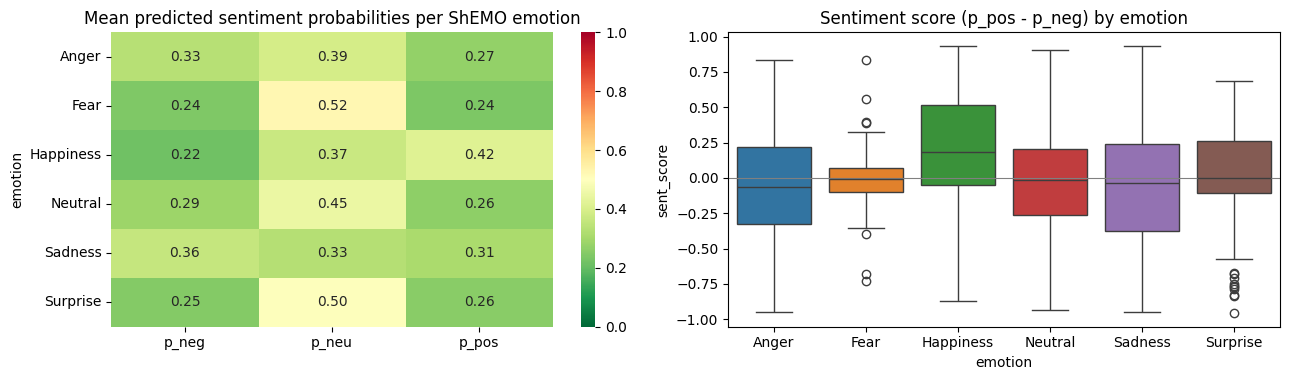

In [44]:
EMO2POL = {"Anger": "negative", "Sadness": "negative", "Fear": "negative", "Happiness": "positive", "Neutral": "neutral"}
sub = df[df.emotion.isin(EMO2POL) & (df.sent_label != "empty")].copy()
y_true, y_pred = sub.emotion.map(EMO2POL), sub.sent_label
base = y_true.value_counts(normalize=True).max()
print(f"utterances evaluated: {len(sub)} | majority-class baseline accuracy: {base:.3f}")
print(f"text-sentiment vs emotion polarity -> Acc {accuracy_score(y_true, y_pred):.3f} | "
      f"UAR {balanced_accuracy_score(y_true, y_pred):.3f} | macro-F1 {f1_score(y_true, y_pred, average='macro', zero_division=0):.3f}")
display(pd.DataFrame(classification_report(y_true, y_pred, labels=POL, output_dict=True, zero_division=0)).T.round(3))

mean_p = df[df.sent_label != "empty"].groupby("emotion")[["p_neg", "p_neu", "p_pos"]].mean()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
sns.heatmap(mean_p, annot=True, fmt=".2f", cmap="RdYlGn_r", ax=ax[0], vmin=0, vmax=1)
ax[0].set_title("Mean predicted sentiment probabilities per ShEMO emotion")
sns.boxplot(data=df[df.sent_label != "empty"], x="emotion", y="sent_score", ax=ax[1], hue="emotion", legend=False)
ax[1].axhline(0, color="gray", lw=0.8); ax[1].set_title("Sentiment score (p_pos - p_neg) by emotion")
plt.tight_layout(); plt.savefig(WORK / "sentiment_by_emotion.png", dpi=150); plt.show()

if HAS_REFS:
    has_ref = df.ref.notna() & (df.ref.astype(str).str.strip() != "")
    dref = df[has_ref].copy()
    add_sentiment(dref, "ref", "ref_")
    cmp_ = dref.merge(ev[["stem", "wer_utt"]], on="stem", how="inner")
    cmp_ = cmp_[(cmp_.sent_label != "empty") & (cmp_.ref_sent_label != "empty")]
    cmp_["agree"] = cmp_.sent_label == cmp_.ref_sent_label
    cmp_["wer_bucket"] = pd.cut(cmp_.wer_utt, [-0.001, 0.0, 0.2, 0.5, 10], labels=["0 (perfect)", "(0, 20%]", "(20%, 50%]", "> 50%"])
    print(f"\nsentiment label agreement, reference text vs ASR text: {cmp_.agree.mean():.1%} (n={len(cmp_)})")
    print(f"correlation of sentiment scores (ref vs ASR): {np.corrcoef(cmp_.ref_sent_score, cmp_.sent_score)[0, 1]:.3f}")
    display(cmp_.groupby("wer_bucket", observed=True).agg(n=("agree", "size"), agreement=("agree", "mean")).round(3))
    if "ref_sent_label" in dref:
        sub_r = dref[dref.emotion.isin(EMO2POL) & (dref.ref_sent_label != "empty")]
        print(f"for comparison, sentiment of the REFERENCE text vs emotion polarity: Acc "
              f"{accuracy_score(sub_r.emotion.map(EMO2POL), sub_r.ref_sent_label):.3f} (n={len(sub_r)})")

<div dir="rtl" align="right">

## ۱۰. استفاده‌ی سرتاسری روی یک فایل

`analyze_audio(path)`: صوت ← (برش در صورت نیاز) ← Whisper ← sentiment. برای فایل خودتان در Colab می‌توانید با `from google.colab import files; files.upload()` فایل را بارگذاری کنید و مسیر را بدهید.

</div>

In [45]:
def analyze_audio(path, show=True):
    wav = load_audio(path)
    dur = len(wav) / CFG.sr
    t0 = time.time()
    chunks = file_chunks(wav)
    texts, retried = decode_items(chunks) if chunks else ([], [])
    text = " ".join(texts).strip()
    P = sentiment_probs([text])[0][0]
    out = dict(file=Path(path).name, duration_sec=round(dur, 2), n_chunks=len(chunks), transcript=text,
               sentiment=(POL[int(np.nanargmax(P))] if not np.isnan(P).any() else "empty"),
               score=(round(float(P[2] - P[0]), 3) if not np.isnan(P).any() else None),
               probs=dict(zip(POL, np.round(P, 3).tolist())), seconds=round(time.time() - t0, 2))
    if show:
        display(rtl(f"<b>{out['file']}</b> ({dur:.1f}s)<br>{text or '<i>(no speech detected)</i>'}"))
        print({k: out[k] for k in ("sentiment", "score", "probs", "seconds")})
        display(Audio(path))
    return out


demo = df.iloc[len(df) // 2]
print("ShEMO emotion label:", demo.emotion)
_ = analyze_audio(demo.path)

ShEMO emotion label: Neutral


[transformers] Both `max_new_tokens` (=225) and `max_length`(=448) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


{'sentiment': 'negative', 'score': -0.785, 'probs': {'negative': 0.82, 'neutral': 0.145, 'positive': 0.035}, 'seconds': 1.83}


<div dir="rtl" align="right">

## ۱۱. (اختیاری) مقایسه‌ی رمزگشایی: greedy در برابر beam search

برای اینکه ادعای «beam بهتر است» را خودتان روی داده‌ی خودتان بسنجید. نیازمند متن مرجع است و حدود چند دقیقه طول می‌کشد (۱۲۰ جمله، دو بار رمزگشایی). برای اجرا `RUN_ABLATION = True` بگذارید.

</div>

In [46]:
RUN_ABLATION = False

if RUN_ABLATION and HAS_REFS:
    sub_ab = ev.sample(min(120, len(ev)), random_state=CFG.seed)
    chunks_ab = [load_audio(p) for p in sub_ab.path]
    rows_ab, saved = [], (CFG.num_beams, CFG.repetition_guard)
    for beams, guard in ((1, False), (1, True), (5, False), (5, True)):
        CFG.num_beams, CFG.repetition_guard = beams, guard
        hyps, _ = decode_items([c if len(c) <= CFG.chunk_sec * CFG.sr else c[:int(CFG.chunk_sec * CFG.sr)] for c in chunks_ab])
        e = pd.DataFrame([utt_errors(r, h) for r, h in zip(sub_ab.ref, hyps)])
        rows_ab.append(dict(beams=beams, repetition_guard=guard, WER=e.w_err.sum() / e.n_ref_words.sum(),
                            CER=e.c_err.sum() / e.n_ref_chars.sum()))
    CFG.num_beams, CFG.repetition_guard = saved
    display(pd.DataFrame(rows_ab).round(4))

<div dir="rtl" align="right">

## ۱۲. ذخیره‌ی نتایج و گام‌های بعدی

</div>

In [47]:
cols = ["file", "speaker", "gender", "emotion", "duration", "hyp", "n_chunks", "retried",
        "p_neg", "p_neu", "p_pos", "sent_label", "sent_score"]
final = df[cols + (["ref"] if HAS_REFS else [])]
final.to_csv(WORK / "asr_sentiment_results.csv", index=False, encoding="utf-8-sig")   # utf-8-sig: opens correctly in Excel
json.dump(asdict(CFG), open(WORK / "config.json", "w"), ensure_ascii=False, indent=2)
print("saved:", WORK / "asr_sentiment_results.csv")
# Colab download:  from google.colab import files; files.download(str(WORK / "asr_sentiment_results.csv"))

saved: /content/asr_outputs/asr_sentiment_results.csv


<div dir="rtl" align="right">

**گام‌های بعدی پیشنهادی**

1. **Fine-tune کردن Whisper** روی بخشی از ShEMO یا یک پیکره‌ی بزرگ‌تر فارسی (مثلاً Common Voice فارسی) با LoRA، و سنجش اثر آن روی WER به تفکیک احساس.
2. **اتصال به پروژه‌ی SER:** احساس صدا (از مدل SER) و احساس متن (همین نوتبوک) را در یک مدل **چندوجهی** (late fusion یا concat) ترکیب کنید و ببینید تکلیف کلاس‌های مبهم (مثلاً Neutral در برابر Sadness) چقدر بهتر می‌شود.
3. **مدل sentiment متناسب‌تر:** fine-tune کردن یک مدل کوچک روی چند صد جمله‌ی برچسب‌خورده‌ی خودتان از گفتار محاوره‌ای.
4. **ارزیابی املا-مستقل‌تر:** نگاشت محاوره‌ای ← معیار (مثلاً «میگرده» ← «می‌گردد») پیش از محاسبه‌ی WER.
5. **Timestamp و diarization** برای صوت‌های بلند و چندگوینده‌ای.

</div>